# Q2 · Part B (analysis) — Comparative analysis: Decision Tree vs Random Forest vs SVM

Combines the results of both datasets: **experimental results**, **overall framework** and **end-to-end analysis**.
Run `01_Q2_Heart_Disease.ipynb` and `02_Q2_Intel_Images.ipynb` first.

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from lab_utils import load_json, save_json, savefig
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
H = load_json(ROOT / "results" / "q2" / "heart_results.json")
I = load_json(ROOT / "results" / "q2" / "intel_results.json")

## 1. Experimental results — all models, both datasets

In [3]:
def table(res, label):
    d = pd.DataFrame(res["comparison"]); d.insert(0, "dataset", label); return d
all_df = pd.concat([table(H, "Heart Disease"), table(I, "Intel Images")], ignore_index=True)
short = {"Decision Tree": "DT", "Random Forest": "RF", "SVM": "SVM"}
all_df["short"] = all_df["model"].map(lambda s: next(v for k, v in short.items() if s.startswith(k)))
display(all_df.drop(columns="short").round(4))
if "tuned" in H: display(pd.DataFrame(H["tuned"]).round(4))

,dataset,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc
0,Heart Disease,Decision Tree (default),0.7833,0.8000,0.7143,0.7547,0.0028,0.0002,0.7790
1,Heart Disease,"Random Forest (default, 100 trees)",0.8833,0.9565,0.7857,0.8627,0.3300,0.0585,0.9448
2,Heart Disease,"SVM (RBF, default)",0.9000,1.0000,0.7857,0.8800,0.0059,0.0014,0.9397
3,Intel Images,Decision Tree (default),0.4460,0.4460,0.4464,0.4459,152.5700,0.0260,0.6679
4,Intel Images,"Random Forest (default, 100 trees)",0.6007,0.5948,0.5984,0.5924,79.3932,0.2535,0.8784
5,Intel Images,SVM (RBF + PCA-100),0.6477,0.6457,0.6463,0.6425,41.5430,13.5136,NaN


,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc,cv_best_score
0,Decision Tree (tuned),0.7667,0.7692,0.7143,0.7407,0.0026,0.0006,0.8092,0.7725
1,Random Forest (tuned),0.8833,0.9565,0.7857,0.8627,0.2511,0.0396,0.9448,0.8231
2,SVM (tuned),0.8667,1.0000,0.7143,0.8333,0.0059,0.0024,0.9230,0.8274


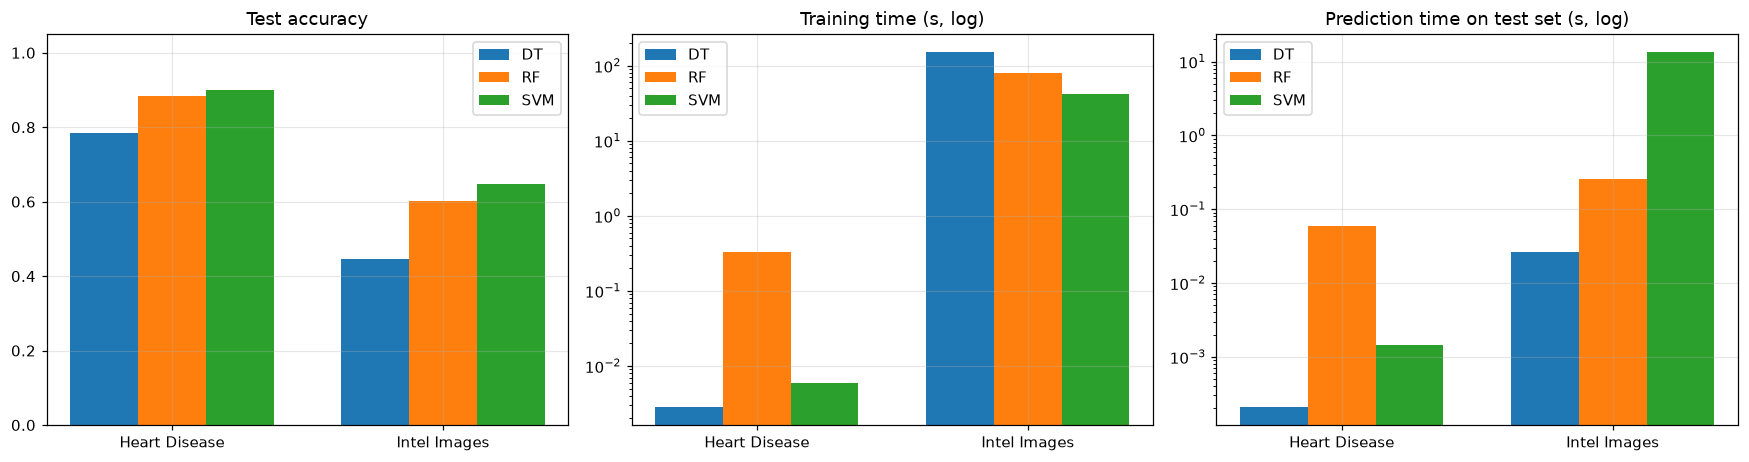

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
x = np.arange(2); w = 0.25
for k, m in enumerate(["DT", "RF", "SVM"]):
    sub = all_df[all_df.short == m]
    axes[0].bar(x + (k - 1) * w, sub["accuracy"], w, label=m)
    axes[1].bar(x + (k - 1) * w, sub["train_time_s"], w, label=m)
    axes[2].bar(x + (k - 1) * w, sub["predict_time_s"], w, label=m)
for ax, t in zip(axes, ["Test accuracy", "Training time (s, log)", "Prediction time on test set (s, log)"]):
    ax.set_xticks(x); ax.set_xticklabels(["Heart Disease", "Intel Images"]); ax.set_title(t); ax.legend()
axes[1].set_yscale("log"); axes[2].set_yscale("log"); axes[0].set_ylim(0, 1.05)
plt.tight_layout(); savefig(fig, "q2", "comparison_all"); plt.show()

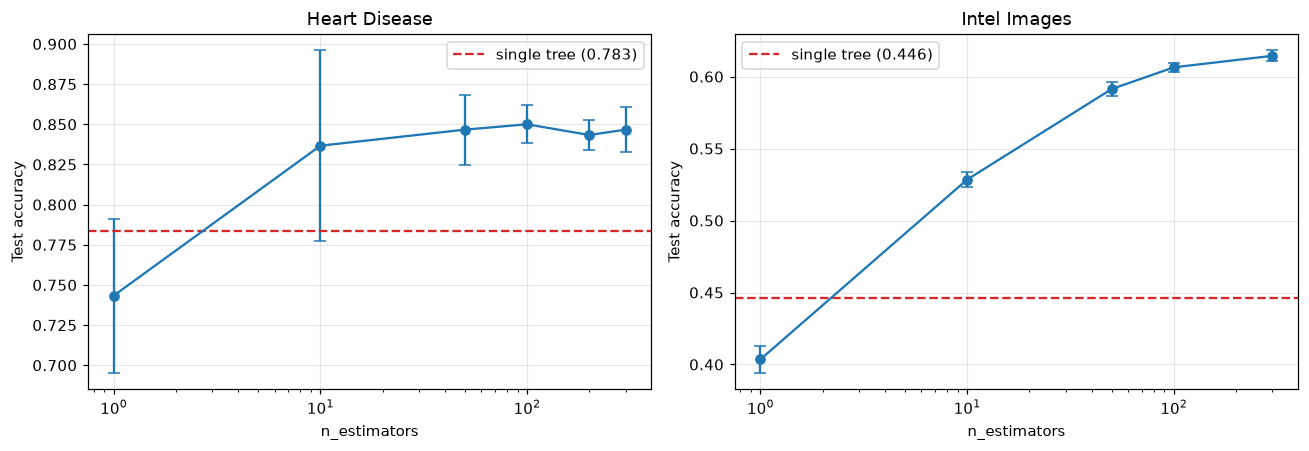

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, R, t in zip(axes, [H, I], ["Heart Disease", "Intel Images"]):
    s = pd.DataFrame(R["sweep_summary"])
    ax.errorbar(s.n_estimators, s.test_acc_mean, yerr=s.test_acc_std, fmt="o-", capsize=4)
    dt_acc = R["dt_vs_rf"][0]["accuracy"]; ax.axhline(dt_acc, color="tab:red", ls="--", label=f"single tree ({dt_acc:.3f})")
    ax.set_xscale("log"); ax.set_xlabel("n_estimators"); ax.set_ylabel("Test accuracy"); ax.set_title(t); ax.legend()
plt.tight_layout(); savefig(fig, "q2", "sweep_both"); plt.show()

## 2. Overall framework
The same end-to-end pipeline is used for every dataset and model so that the comparison is fair.

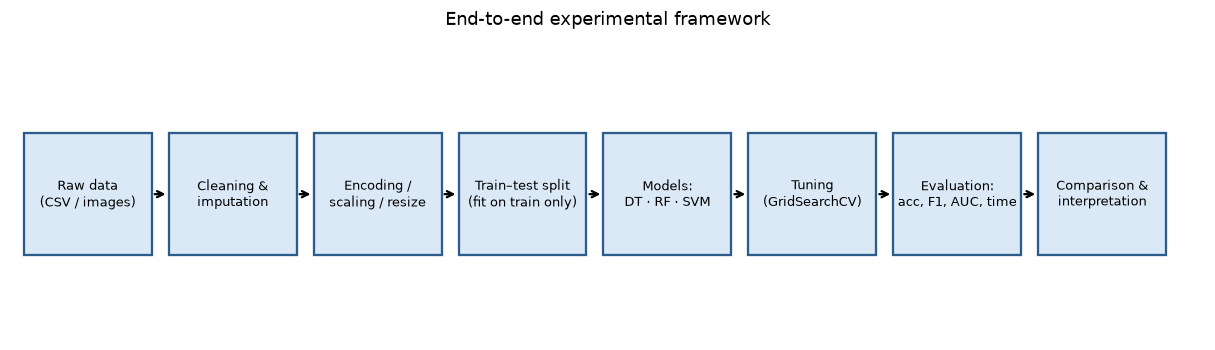

In [6]:
fig, ax = plt.subplots(figsize=(14, 3.6)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 4)
steps = ["Raw data\n(CSV / images)", "Cleaning &\nimputation", "Encoding /\nscaling / resize", "Train–test split\n(fit on train only)",
         "Models:\nDT · RF · SVM", "Tuning\n(GridSearchCV)", "Evaluation:\nacc, F1, AUC, time", "Comparison &\ninterpretation"]
for i, s in enumerate(steps):
    xc = 0.9 + i * 1.7
    ax.add_patch(plt.Rectangle((xc - 0.75, 1.1), 1.5, 1.6, fc="#dbe9f7", ec="#2b5c8a", lw=1.5))
    ax.text(xc, 1.9, s, ha="center", va="center", fontsize=8.5)
    if i < len(steps) - 1: ax.annotate("", xy=(xc + 0.95, 1.9), xytext=(xc + 0.75, 1.9), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_title("End-to-end experimental framework", fontsize=12)
savefig(fig, "q2", "framework"); plt.show()

## 3. End-to-end analysis (numbers filled in automatically)

In [ ]:
def get(R, prefix, key):
    return next(r for r in R["comparison"] if r["model"].startswith(prefix))[key]

lines = []
for R, name in [(H, "Heart Disease"), (I, "Intel Images")]:
    dt, rf, sv = (get(R, p, "accuracy") for p in ["Decision Tree", "Random Forest", "SVM"])
    tdt, trf, tsv = (get(R, p, "train_time_s") for p in ["Decision Tree", "Random Forest", "SVM"])
    best = max([("Decision Tree", dt), ("Random Forest", rf), ("SVM", sv)], key=lambda t: t[1])
    s = pd.DataFrame(R["sweep_summary"])
    lines.append(f"**{name}.** Test accuracy: Decision Tree {dt:.3f}, Random Forest {rf:.3f}, SVM {sv:.3f}; best = {best[0]}. "
                 f"Random Forest improves on the single tree by {100*(rf-dt):+.1f} percentage points but needs about {trf/max(tdt,1e-9):.0f}x more training time "
                 f"({trf:.3f}s vs {tdt:.3f}s). SVM training took {tsv:.3f}s. "
                 f"With 1 tree the forest reached {s.test_acc_mean.iloc[0]:.3f} (std {s.test_acc_std.iloc[0]:.3f} across seeds); with {int(s.n_estimators.iloc[-1])} trees "
                 f"{s.test_acc_mean.iloc[-1]:.3f} (std {s.test_acc_std.iloc[-1]:.3f}).")
ANALYSIS = "\n\n".join(lines)
display(Markdown(ANALYSIS))
save_json({"auto_summary": ANALYSIS}, ROOT / "results" / "q2" / "analysis_text.json")

**Heart Disease.** Test accuracy: Decision Tree 0.783, Random Forest 0.883, SVM 0.900; best = SVM. Random Forest improves on the single tree by +10.0 percentage points but needs about 117x more training time (0.330s vs 0.003s). SVM training took 0.006s. With 1 tree the forest reached 0.743 (std 0.048 across seeds); with 300 trees 0.847 (std 0.014).

**Intel Images.** Test accuracy: Decision Tree 0.446, Random Forest 0.601, SVM 0.648; best = SVM. Random Forest improves on the single tree by +15.5 percentage points but needs about 1x more training time (79.393s vs 152.570s). SVM training took 41.543s. With 1 tree the forest reached 0.404 (std 0.009 across seeds); with 300 trees 0.614 (std 0.004).

: 

## 4. Discussion guide (write this in your own words in the report)
* **Tabular data (small, mixed types):** SVM and Random Forest are usually close; the single tree is the least stable (high variance — it changes a lot with the data/seed).
* **Image pixels (high-dimensional, 3072 features):** raw pixels are a weak representation for all three models; the forest averages many noisy trees and clearly beats one tree, the SVM (with PCA) is often competitive but slower to train and predict.
* **Ensemble size:** accuracy rises quickly for the first ~50 trees and then plateaus; the *standard deviation across seeds* keeps shrinking — more trees buy **stability**, not unlimited accuracy.
* **Cost:** training/prediction time grows linearly with the number of trees (but trees are independent, so `n_jobs=-1` parallelises them).
* **Limitations:** one train/test split, raw pixels (a CNN would reach 85–90 %+), default hyper-parameters for the image data.